
# Stage 6: Hyperparameter Tuning and Model Evaluation

## 6.1 Introduction

This stage focuses on improving and evaluating the machine learning models developed in Stage 5. Hyperparameter tuning will be used to identify suitable model settings, and evaluation metrics will be used to compare performance.

The goal is to select a reliable model for predicting hotel booking cancellations and explain how its predictions can support hotel management decisions.



## 6.2 Import Libraries and Check Files

In this step, we import the Python libraries needed for model tuning and evaluation, and check that the prepared dataset and Stage 5 results are available.

In [18]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

files = [
    "hotel_bookings_model_ready.csv",
    "stage5_model_comparison.csv"
]

for file in files:
    print(file, ":", os.path.exists(file))


Libraries imported successfully!
hotel_bookings_model_ready.csv : True
stage5_model_comparison.csv : True



## 6.3 Load Dataset and Review Stage 5 Results

This step loads the prepared hotel booking dataset and reviews the model comparison results from Stage 5. These results will be used as a baseline for evaluating the tuned models.


In [19]:

df = pd.read_csv("hotel_bookings_model_ready.csv")

stage5_results = pd.read_csv("stage5_model_comparison.csv")

print("Dataset Shape:", df.shape)

print("\nStage 5 Model Comparison:")
display(stage5_results)

print("\nDataset Columns:")
print(df.columns.tolist())


Dataset Shape: (119209, 33)

Stage 5 Model Comparison:


,Model,CV F1,CV ROC-AUC,Test F1,Test ROC-AUC,Test Precision,Test Recall,Time-split ROC-AUC,Fit time (s)
0,Baseline (majority class),0.0000,0.5000,0.0000,0.5000,0.0000,0.0000,0.5000,0.3802
1,Logistic Regression,0.5832,0.8550,0.5826,0.8561,0.6807,0.5092,0.8329,1.6410
2,Decision Tree,0.6520,0.8822,0.6504,0.8907,0.7349,0.5834,0.7986,0.8463
3,Random Forest,0.6958,0.9062,0.7012,0.9091,0.7715,0.6426,0.8368,2.7560
4,Gradient Boosting (HistGB),0.7005,0.9110,0.7018,0.9143,0.7470,0.6618,0.8441,3.6787



Dataset Columns:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'total_guests', 'total_nights', 'total_previous_bookings']


## 6.4 Data Preparation (Same as Stage 5)

We use exactly the same preparation as Stage 5, so the tuned models can be compared fairly with the Stage 5 results:

- `assigned_room_type` is dropped (leakage, see Stage 5 section 5.2).
- `company` is replaced by `has_company`, and `agent` is treated as a category.
- Duplicate rows are removed for modelling only, so identical rows cannot appear in both the training and test sets.
- 80/20 stratified train/test split with `random_state = 42`.

In [20]:

def prepare_features(data):
    d = data.copy()

    d = d.drop(columns=["assigned_room_type"])
    d["has_company"] = (d["company"] > 0).astype(int)
    d = d.drop(columns=["company"])

    d["agent"] = d["agent"].astype(int).astype(str)
    d["children"] = d["children"].astype(int)
    d["total_guests"] = d["total_guests"].astype(int)

    return d

RANDOM_STATE = 42

df_prepared = prepare_features(df)

df_dedup = df_prepared.drop_duplicates().reset_index(drop=True)

print("Rows before preparation:", len(df))
print("Rows after preparation and duplicate removal:", len(df_dedup))
print("Columns after preparation:", df_dedup.shape[1])


Rows before preparation: 119209
Rows after preparation and duplicate removal: 85975
Columns after preparation: 32



## 6.5 Train-Test Split

The prepared dataset is divided into 80% training data and 20% testing data. Stratified sampling is used to maintain the same cancellation distribution in both datasets. The random state is set to 42 for reproducibility.


In [21]:

# Separate features and target
X = df_dedup.drop(columns=["is_canceled"])
y = df_dedup["is_canceled"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Training columns:", X_train.shape[1])
print("Testing columns:", X_test.shape[1])


Training rows: 68780
Testing rows: 17195
Training columns: 31
Testing columns: 31



## 6.6 Prepare Models for Hyperparameter Tuning

Random Forest and Gradient Boosting were selected because they achieved strong performance in Stage 5. The same preprocessing approach is used to ensure a fair comparison. Hyperparameter tuning will be performed using cross-validation on the training data.


In [22]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

CAT_COLS = [
    "hotel", "arrival_date_month", "meal", "country",
    "market_segment", "distribution_channel",
    "reserved_room_type", "deposit_type",
    "customer_type", "agent"
]

def make_preprocessor(scale_numeric=False):
    numeric_cols = [
        col for col in X_train.columns
        if col not in CAT_COLS
    ]

    transformers = [
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=100,
            sparse_output=False
        ), CAT_COLS)
    ]

    if scale_numeric:
        transformers.append(
            ("num", StandardScaler(), numeric_cols)
        )
    else:
        transformers.append(
            ("num", "passthrough", numeric_cols)
        )

    return ColumnTransformer(transformers)

print("Preprocessing function created successfully!")



Preprocessing function created successfully!


In [23]:

# Prepare Random Forest
rf_pipeline = Pipeline([
    ("pre", make_preprocessor(False)),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

# Prepare Gradient Boosting
gb_pipeline = Pipeline([
    ("pre", make_preprocessor(False)),
    ("model", HistGradientBoostingClassifier(
        random_state=42
    ))
])

print("Random Forest pipeline created successfully!")
print("Gradient Boosting pipeline created successfully!")


Random Forest pipeline created successfully!
Gradient Boosting pipeline created successfully!



## 6.7 Verify Preprocessing Consistency

The preprocessing configuration is checked against Stage 5 before hyperparameter tuning to ensure a consistent and fair model comparison.


In [24]:

# Show our Stage 6 preprocessing configuration
print("Categorical columns:")
print(CAT_COLS)

print("\nPreprocessing configuration:")
print(make_preprocessor(False))

print("\nTraining data shape:")
print(X_train.shape)


Categorical columns:
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type', 'agent']

Preprocessing configuration:
ColumnTransformer(transformers=[('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               min_frequency=100,
                                               sparse_output=False),
                                 ['hotel', 'arrival_date_month', 'meal',
                                  'country', 'market_segment',
                                  'distribution_channel', 'reserved_room_type',
                                  'deposit_type', 'customer_type', 'agent']),
                                ('num', 'passthrough',
                                 ['lead_time', 'arrival_date_year',
                                  'arrival_date_week_number',
                                  'arr...e_day_of_month',
        


## 6.8 Random Forest Hyperparameter Tuning

RandomizedSearchCV is used to test different Random Forest hyperparameters. Five-fold stratified cross-validation is applied to the training data, using ROC-AUC as the evaluation metric. The best parameter combination will be selected for further evaluation.


In [25]:

# Random Forest hyperparameter tuning

rf_params = {
    "model__n_estimators": [100, 150],
    "model__max_depth": [10, 20, None],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_params,
    n_iter=5,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Starting Random Forest tuning...")

rf_search.fit(X_train, y_train)

print("Best Parameters:", rf_search.best_params_)
print("Best CV ROC-AUC:", round(rf_search.best_score_, 4))


Starting Random Forest tuning...
Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best Parameters: {'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_depth': None}
Best CV ROC-AUC: 0.9086


### 6.9 Evaluation of the Tuned Random Forest

The best Random Forest model is evaluated using the testing dataset to measure its performance on unseen data.

In [26]:
# Get the best tuned Random Forest model
best_rf = rf_search.best_estimator_

# Predict on the testing dataset
rf_pred = best_rf.predict(X_test)
rf_prob = best_rf.predict_proba(X_test)[:, 1]

# Evaluate performance
print("Tuned Random Forest Test Results:")
print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred), 4))
print("Recall:", round(recall_score(y_test, rf_pred), 4))
print("F1 Score:", round(f1_score(y_test, rf_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))

Tuned Random Forest Test Results:
Accuracy: 0.8499
Precision: 0.776
Recall: 0.6407
F1 Score: 0.7019
ROC-AUC: 0.912


### 6.10 Confusion Matrix

The confusion matrix shows how many bookings were correctly and incorrectly classified by the tuned Random Forest model.

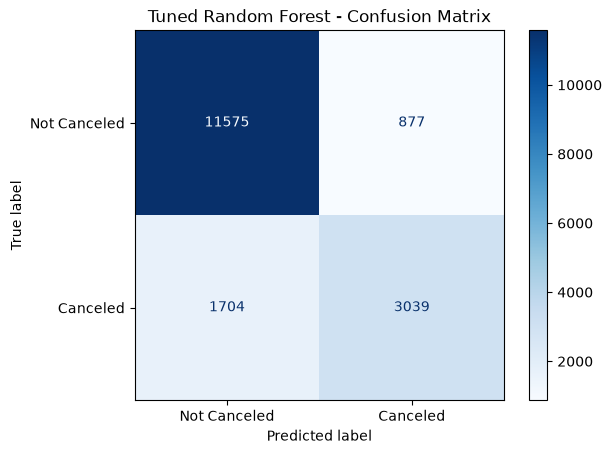

In [27]:
# Confusion Matrix for Tuned Random Forest
cm = confusion_matrix(y_test, rf_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Canceled", "Canceled"]
)

disp.plot(cmap="Blues")
plt.title("Tuned Random Forest - Confusion Matrix")
plt.show()

**Interpretation**

The tuned Random Forest model correctly predicted 11,575 non-canceled bookings and 3,039 canceled bookings. However, it incorrectly predicted 877 bookings as canceled and missed 1,704 actual cancellations. Overall, the model achieved 84.99% accuracy. The results show good performance, but the model could be improved to identify more cancellations.

### 6.11 Gradient Boosting Hyperparameter Tuning

RandomizedSearchCV is used with 5-fold stratified cross-validation to find the best hyperparameters for the Gradient Boosting model. ROC-AUC is used to select the best combination.

In [28]:
# Hyperparameter options for Gradient Boosting
gb_params = {
    "model__learning_rate": [0.05, 0.1, 0.2],
    "model__max_iter": [100, 150, 200],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__min_samples_leaf": [20, 30, 50]
}

# Use the same 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Randomized Search
gb_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=gb_params,
    n_iter=5,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Starting Gradient Boosting tuning...")

gb_search.fit(X_train, y_train)

print("Best Parameters:", gb_search.best_params_)
print("Best CV ROC-AUC:", round(gb_search.best_score_, 4))

Starting Gradient Boosting tuning...
Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best Parameters: {'model__min_samples_leaf': 30, 'model__max_leaf_nodes': 31, 'model__max_iter': 200, 'model__learning_rate': 0.05}
Best CV ROC-AUC: 0.9113


### 6.12 Evaluation of the Tuned Gradient Boosting

The best Gradient Boosting model is evaluated on the testing dataset using accuracy, precision, recall, F1 score, and ROC-AUC.

In [29]:
# Get the best tuned Gradient Boosting model
best_gb = gb_search.best_estimator_

# Predict on the testing dataset
gb_pred = best_gb.predict(X_test)
gb_prob = best_gb.predict_proba(X_test)[:, 1]

# Evaluate performance
print("Tuned Gradient Boosting Test Results:")
print("Accuracy:", round(accuracy_score(y_test, gb_pred), 4))
print("Precision:", round(precision_score(y_test, gb_pred), 4))
print("Recall:", round(recall_score(y_test, gb_pred), 4))
print("F1 Score:", round(f1_score(y_test, gb_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, gb_prob), 4))

Tuned Gradient Boosting Test Results:
Accuracy: 0.8464
Precision: 0.7513
Recall: 0.6624
F1 Score: 0.7041
ROC-AUC: 0.9144


### 6.13 Comparison of Tuned Models

The tuned Random Forest and Gradient Boosting models are compared using accuracy, precision, recall, F1 score, and ROC-AUC to identify the most suitable model for predicting hotel booking cancellations.

In [30]:
# Compare tuned models
comparison = pd.DataFrame({
    "Model": ["Random Forest", "Gradient Boosting"],
    "Accuracy": [
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, gb_pred)
    ],
    "Precision": [
        precision_score(y_test, rf_pred),
        precision_score(y_test, gb_pred)
    ],
    "Recall": [
        recall_score(y_test, rf_pred),
        recall_score(y_test, gb_pred)
    ],
    "F1 Score": [
        f1_score(y_test, rf_pred),
        f1_score(y_test, gb_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, rf_prob),
        roc_auc_score(y_test, gb_prob)
    ]
})

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.8499,0.7760,0.6407,0.7019,0.9120
1,Gradient Boosting,0.8464,0.7513,0.6624,0.7041,0.9144


### 6.14 Before vs After Tuning

This table compares the Stage 5 models (near-default settings) with the tuned models, to show how much hyperparameter tuning improved performance.

In [31]:
s5 = stage5_results.set_index("Model")

before_after = pd.DataFrame({
    "CV ROC-AUC (Stage 5)": [s5.loc["Random Forest", "CV ROC-AUC"], s5.loc["Gradient Boosting (HistGB)", "CV ROC-AUC"]],
    "CV ROC-AUC (tuned)": [rf_search.best_score_, gb_search.best_score_],
    "Test ROC-AUC (Stage 5)": [s5.loc["Random Forest", "Test ROC-AUC"], s5.loc["Gradient Boosting (HistGB)", "Test ROC-AUC"]],
    "Test ROC-AUC (tuned)": [roc_auc_score(y_test, rf_prob), roc_auc_score(y_test, gb_prob)],
    "Test F1 (Stage 5)": [s5.loc["Random Forest", "Test F1"], s5.loc["Gradient Boosting (HistGB)", "Test F1"]],
    "Test F1 (tuned)": [f1_score(y_test, rf_pred), f1_score(y_test, gb_pred)],
}, index=["Random Forest", "Gradient Boosting"])

before_after["ROC-AUC change"] = before_after["Test ROC-AUC (tuned)"] - before_after["Test ROC-AUC (Stage 5)"]
before_after["F1 change"] = before_after["Test F1 (tuned)"] - before_after["Test F1 (Stage 5)"]

display(before_after.round(4))

,CV ROC-AUC (Stage 5),CV ROC-AUC (tuned),Test ROC-AUC (Stage 5),Test ROC-AUC (tuned),Test F1 (Stage 5),Test F1 (tuned),ROC-AUC change,F1 change
Random Forest,0.9062,0.9086,0.9091,0.9120,0.7012,0.7019,0.0029,0.0007
Gradient Boosting,0.9110,0.9113,0.9143,0.9144,0.7018,0.7041,0.0001,0.0023


**Interpretation**

Hyperparameter tuning produced small improvements in both models. For Random Forest, the cross-validation ROC-AUC increased from 0.9062 to 0.9086, the test ROC-AUC increased from 0.9091 to 0.9120, and the test F1 score improved from 0.7012 to 0.7019.

For Gradient Boosting, the cross-validation ROC-AUC increased from 0.9110 to 0.9113. The test ROC-AUC showed almost no change, increasing from 0.9143 to 0.9144, while the test F1 score improved from 0.7018 to 0.7041.

The improvements were small because the original model settings may already have been effective, or the available features may have limited further improvement. Another limitation is that RandomizedSearchCV tested only five hyperparameter combinations for each model. A wider search could potentially identify better settings.

Gradient Boosting was selected as the preferred model because it achieved the highest cross-validation ROC-AUC of 0.9113. The test results supported this choice, as it also achieved the highest test ROC-AUC and F1 score.

### 6.15 Choosing the Decision Threshold

By default, a booking is predicted as "canceled" when its probability is at least 0.5. The hotel can change this threshold:

- A **lower** threshold catches more cancellations (higher recall) but gives more false alarms (lower precision).
- A **higher** threshold gives fewer false alarms but misses more cancellations.

To avoid using the test set for this decision, the threshold is chosen from **cross-validated predictions on the training data** (each booking is predicted by a model that did not see it during training).

,Precision,Recall,F1 Score,False alarms (FP),Missed cancellations (FN)
Threshold,,,,,
0.25,0.596,0.883,0.712,11333,2220
0.30,0.632,0.840,0.721,9289,3036
0.35,0.665,0.795,0.724,7610,3895
0.40,0.696,0.751,0.723,6215,4724
0.45,0.722,0.707,0.714,5166,5562
0.50,0.745,0.661,0.700,4286,6435
0.55,0.769,0.614,0.683,3495,7326
0.60,0.795,0.558,0.656,2725,8381


Threshold with the highest F1 score: 0.35


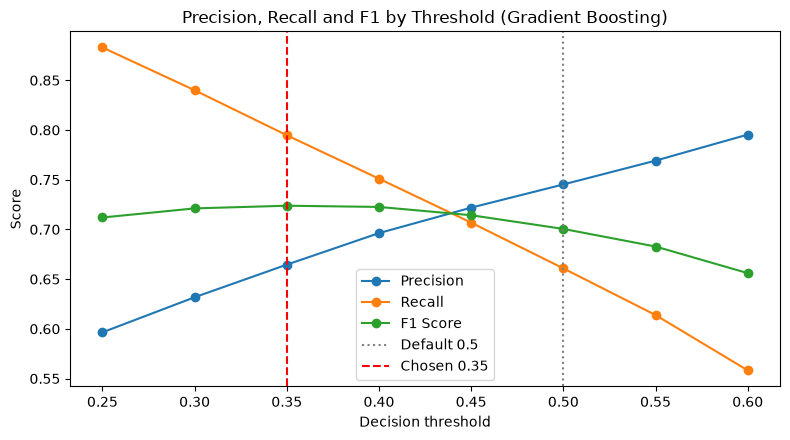

In [32]:
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone

oof_prob = cross_val_predict(clone(best_gb), X_train, y_train, cv=cv,
                             method="predict_proba", n_jobs=-1)[:, 1]

rows = []
for t in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    pred = (oof_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    rows.append({
        "Threshold": t,
        "Precision": precision_score(y_train, pred),
        "Recall": recall_score(y_train, pred),
        "F1 Score": f1_score(y_train, pred),
        "False alarms (FP)": fp,
        "Missed cancellations (FN)": fn,
    })

threshold_table = pd.DataFrame(rows).set_index("Threshold")
display(threshold_table.round(3))

best_threshold = float(threshold_table["F1 Score"].idxmax())
print("Threshold with the highest F1 score:", best_threshold)

plt.figure(figsize=(8, 4.5))
plt.plot(threshold_table.index, threshold_table["Precision"], marker="o", label="Precision")
plt.plot(threshold_table.index, threshold_table["Recall"], marker="o", label="Recall")
plt.plot(threshold_table.index, threshold_table["F1 Score"], marker="o", label="F1 Score")
plt.axvline(0.5, color="grey", linestyle=":", label="Default 0.5")
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Chosen {best_threshold}")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 by Threshold (Gradient Boosting)")
plt.legend()
plt.tight_layout()
plt.show()

### 6.16 Final Model on the Test Set with the Chosen Threshold

The final Gradient Boosting model is evaluated once on the test set at the default threshold (0.5) and at the chosen threshold.

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Threshold,,,,,
0.50,0.8464,0.7513,0.6624,0.7041,0.9144
0.35,0.8388,0.6758,0.7993,0.7323,0.9144


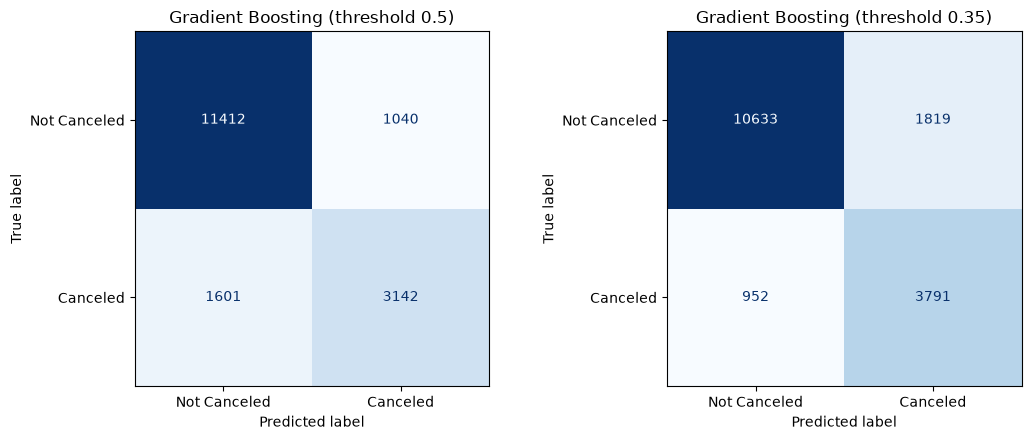

In [33]:
results = []
for t in [0.5, best_threshold]:
    pred = (gb_prob >= t).astype(int)
    results.append({
        "Threshold": t,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1 Score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, gb_prob),
    })
final_results = pd.DataFrame(results).set_index("Threshold")
display(final_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, t in zip(axes, [0.5, best_threshold]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, (gb_prob >= t).astype(int),
        display_labels=["Not Canceled", "Canceled"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"Gradient Boosting (threshold {t})")
    ax.grid(False)
plt.tight_layout()
plt.show()

### Interpretation

The threshold of 0.35 was selected because it achieved the highest F1 score on the cross-validated training predictions. The test F1 score improved from 0.704 to 0.732.

Reducing the threshold from 0.50 to 0.35 increased recall from 66.24% to 79.93%, while precision decreased from 75.13% to 67.58%. Missed cancellations decreased from 1,601 to 952, while false alarms increased from 1,040 to 1,819.

Accuracy decreased slightly from 84.64% to 83.88%, while recall improved significantly. This shows why accuracy alone is not enough to evaluate the model, as it can hide missed cancellations.

From a business perspective, identifying more potential cancellations can help hotels reduce empty rooms and revenue losses. Sending additional reminder emails may cost less than leaving rooms empty.

Hotels can also use different thresholds depending on the business action. A lower threshold is suitable for sending reminders, while a higher threshold may be more appropriate for risky decisions such as overbooking.

### 6.17 Model Limitations and Business Implications

Although the model performed well, it still misses some actual cancellations. Therefore, it should support hotel staff in making decisions rather than replace their judgment.

Removing duplicate records during model preparation reduced the cancellation rate from 37.1% to 27.6%. This means the model was evaluated on data with fewer cancellations than the full dataset. As a result, its precision and recall on real hotel bookings may differ from the reported results.

The model was trained using arrival years from 2015 to 2017. It may not accurately capture booking patterns for newer years, such as 2025 or 2026. The application uses 2017 as the default year, which does not reflect recent booking trends. Additionally, future booking changes are unknown when a reservation is first made.

Country and agent are important features, but their influence may reflect the booking patterns and policies of the two hotels in the dataset. Therefore, the model may not perform equally well in other hotels.

Since the dataset is from 2015 to 2017, customer behavior and hotel policies may have changed. The model should be retrained using more recent data to improve its reliability.

From a business perspective, revenue managers and reservation teams can use the model to identify high-risk bookings, send reminders, request deposits where appropriate, and improve room and staffing plans. Any overbooking decisions should be made cautiously and reviewed by hotel staff rather than performed automatically.

### 6.18 Save the Final Model and Results

The final Gradient Boosting pipeline (preprocessing + model) is saved for the Streamlit app (Stage 7), together with the chosen threshold and the information the app needs.

In [34]:
import json

os.makedirs("models", exist_ok=True)
joblib.dump(best_gb, "models/final_model.joblib", compress=3)

model_info = {
    "model_name": "Gradient Boosting (HistGradientBoostingClassifier)",
    "best_params": {k.replace("model__", ""): v for k, v in gb_search.best_params_.items()},
    "threshold": best_threshold,
    "features": list(X_train.columns),
    "categorical_features": CAT_COLS,
    "category_values": {c: sorted(X_train[c].astype(str).unique().tolist()) for c in CAT_COLS},
    "app_defaults": {"arrival_date_year": 2017, "booking_changes": 0},
    "test_metrics": {k: round(float(v), 4) for k, v in final_results.loc[best_threshold].items()},
}
with open("models/model_info.json", "w") as f:
    json.dump(model_info, f, indent=2, default=str)

comparison.to_csv("stage6_tuned_model_comparison.csv", index=False)

print("Saved: models/final_model.joblib")
print("Saved: models/model_info.json")
print("Saved: stage6_tuned_model_comparison.csv")

Saved: models/final_model.joblib
Saved: models/model_info.json
Saved: stage6_tuned_model_comparison.csv
